# Water-wave surface from a measured refracted checkerboard

A distorted checkerboard encodes the slope of a transparent liquid surface. This is a real optical observation-to-height inverse, rather than tracking the material motion of a painted surface. The separate flat-surface image supplies the reference pattern.

This notebook actively reconstructs every selected pixel with local mathematics. It compares against this task's reproduced modern MIT FCD implementation, which is separately authored from the Wildeman2018 and Moisy2009 method papers. No independent height truth is supplied. The observed recording contains an opaque probe outside the fixed transparent ROI; rows256:897 and columns80:721 define the641-square benchmark. This crop changes the finite periodic boundary and is explicitly part of the bound acquisition.

In [1]:
from pathlib import Path
import os,sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import metrics,phase_residual,figures,export
reference,measurements=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream_reconstruction.npz',allow_pickle=False) as z:upstream=z['reconstruction'][0]
print('Bound measured image',measurements.shape,measurements.dtype)


Bound measured image (641, 641) float32


## Optical model, phase and inverse

For position x, apparent displacement u, mean deflection u0 and relative surface elevation h, the small-slope model is

```math
I(\boldsymbol{x})\simeq I_0(\boldsymbol{x}-\boldsymbol{u}),
\qquad \boldsymbol{u}=-H\nabla h+\boldsymbol{u}_0.
```

Here I0 is the flat-surface reference, I is the observation, H=.0329956084466042m is the supplied layered-optics distance, and positions/heights/displacements use metres. The reference square side is2.2mm. The local calibration infers sample pitch.00031747269890795626m. Detector row increases y and column increases x.

Each of two nonparallel Fourier carriers yields wrapped phase phi=q dot u, with q an angular wave vector in radians per metre. Their phases are unwrapped by the explicit Herraez reliability-sorted graph algorithm. Four wrapped second-difference costs determine pixel reliability; sorted neighbour edges merge integer2*pi offsets through weighted union-find. This replaces the opaque domain unwrapping dependency with readable mathematics and agrees with captured source phases up to a constant phase gauge.

Solve the two linear phase relations for displacement, then set slopes g=-u/H. At nonzero angular frequency(kx,ky), the periodic least-squares height is

```math
\widehat h=\frac{-i k_x\widehat g_x-i k_y\widehat g_y}{k_x^2+k_y^2}.
```

The hat denotes a2D Fourier coefficient and i the imaginary unit. Set its zero mode to zero: output is relative elevation with mean tilt excluded. Odd grid dimensions avoid a source even-grid Nyquist suppression defect independently demonstrated by a known-mode test. The selected original and cleaned implementations use the identical641-square ROI and correct odd-grid branch. The integration is closed form; no artificial optimization loop is added.

In [2]:
start=time.perf_counter();fresh,diagnostics=reconstruct(reference,measurements);runtime=time.perf_counter()-start
variants={};timings={'selected':runtime}
for name,options in [('wrapped_only',{'unwrap':False}),('narrow',{'radius_factor':.75})]:
    start=time.perf_counter();variants[name],_=reconstruct(reference,measurements,**options);timings[name]=time.perf_counter()-start
rows=[]
for name,v in [('Reproduced original',upstream),('Fresh selected',fresh),('Fresh no unwrap',variants['wrapped_only']),('Fresh narrower aperture',variants['narrow'])]:
    rows.append({'method':name,**metrics(v,upstream),'phase_residual_rad':phase_residual(v,diagnostics)[0]})
print('Actual runtimes in seconds:',json.dumps(timings,indent=2))
print('Fresh/reference metrics:',json.dumps(rows,indent=2))
(ROOT/'output').mkdir(exist_ok=True);np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh[None])
proc=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print(proc.stdout);assert proc.returncode==0,proc.stderr


Actual runtimes in seconds: {
  "selected": 4.816225300000951,
  "wrapped_only": 0.21018840000033379,
  "narrow": 5.907747900000686
}
Fresh/reference metrics: [
  {
    "method": "Reproduced original",
    "ncc": 1.0,
    "nrmse": 0.0,
    "phase_residual_rad": 0.14872557562675262
  },
  {
    "method": "Fresh selected",
    "ncc": 1.0,
    "nrmse": 6.134631532689771e-17,
    "phase_residual_rad": 0.14872557562675262
  },
  {
    "method": "Fresh no unwrap",
    "ncc": 0.1666373208056676,
    "nrmse": 0.23413439052147722,
    "phase_residual_rad": 0.4543372201438696
  },
  {
    "method": "Fresh narrower aperture",
    "ncc": 0.9975972699020929,
    "nrmse": 0.00986369527498947,
    "phase_residual_rad": 0.21319421150949272
  }
]


{"status": "pass", "passed": true, "metrics": {"ncc": 0.9999999999999999, "nrmse": 6.162975155645119e-17, "phase_residual": 0.14872557562675262}, "thresholds": {"ncc": {"comparison": ">=", "boundary": 0.999999}, "nrmse": {"comparison": "<=", "boundary": 1e-05}, "phase_residual": {"comparison": "<=", "boundary": 0.15021283138302016}}, "errors": []}



## Measured structure, comparisons and physical residuals

The following figures preserve the source example's height and both phase maps, and add comparisons with the reproduced original result, fresh no-unwrapping and aperture variants, physical displacement units, forward carrier residuals, spatial sections and slope consistency. Every fresh plotted array is computed in the previous cell. Wrapped carrier RMS measures observation agreement; field metrics compare a standard method reference and do not establish true surface accuracy. Mean carrier offsets correspond to the excluded mean tilt, not fitted elevation gain or spatial registration.

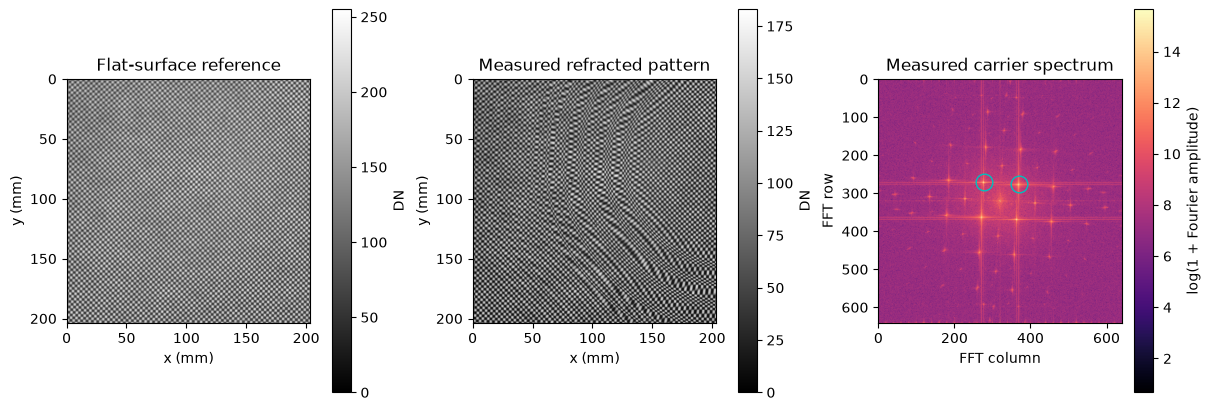

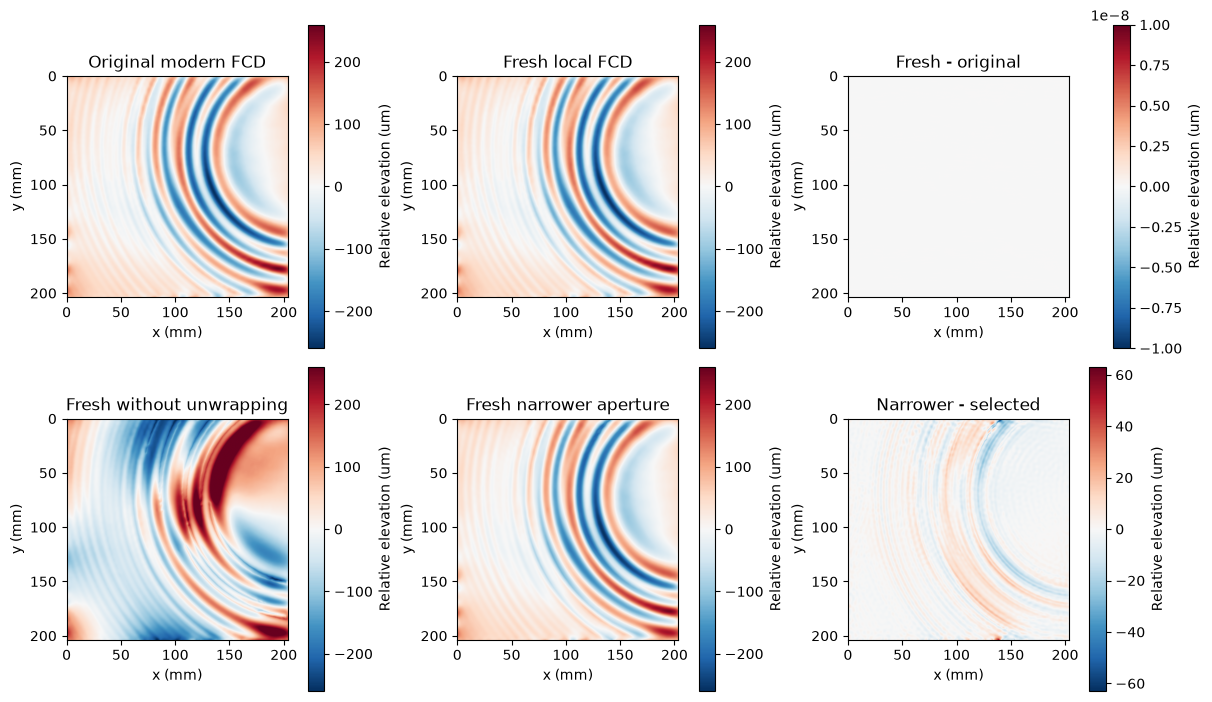

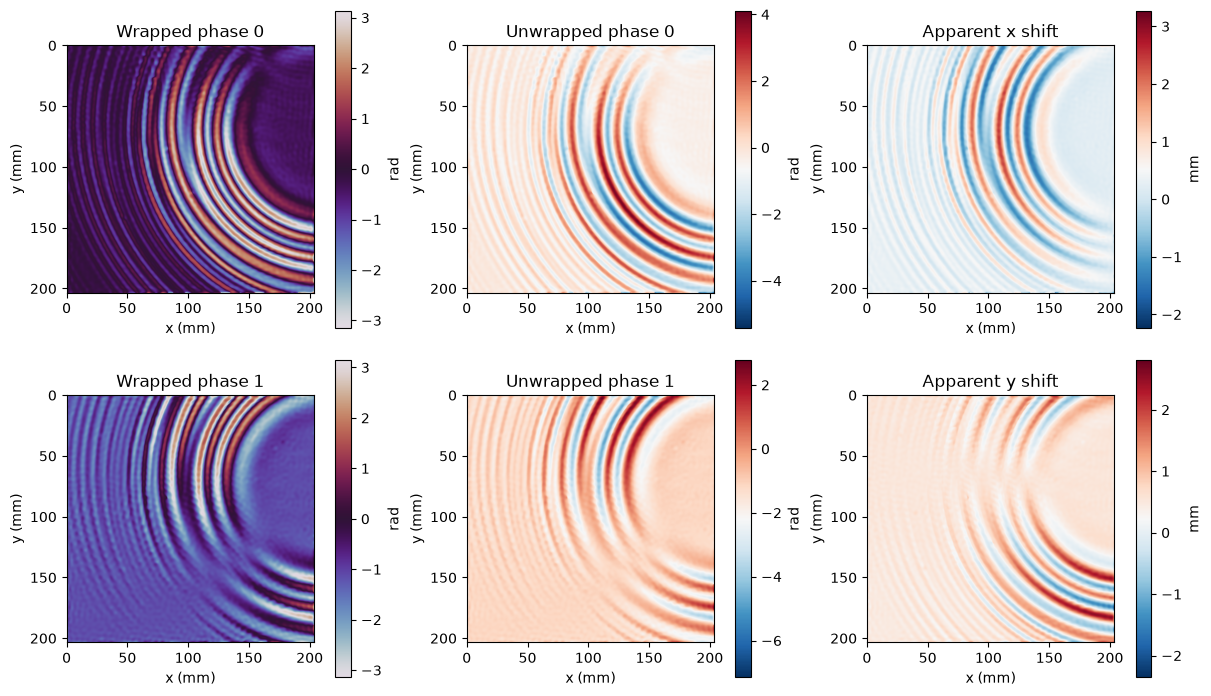

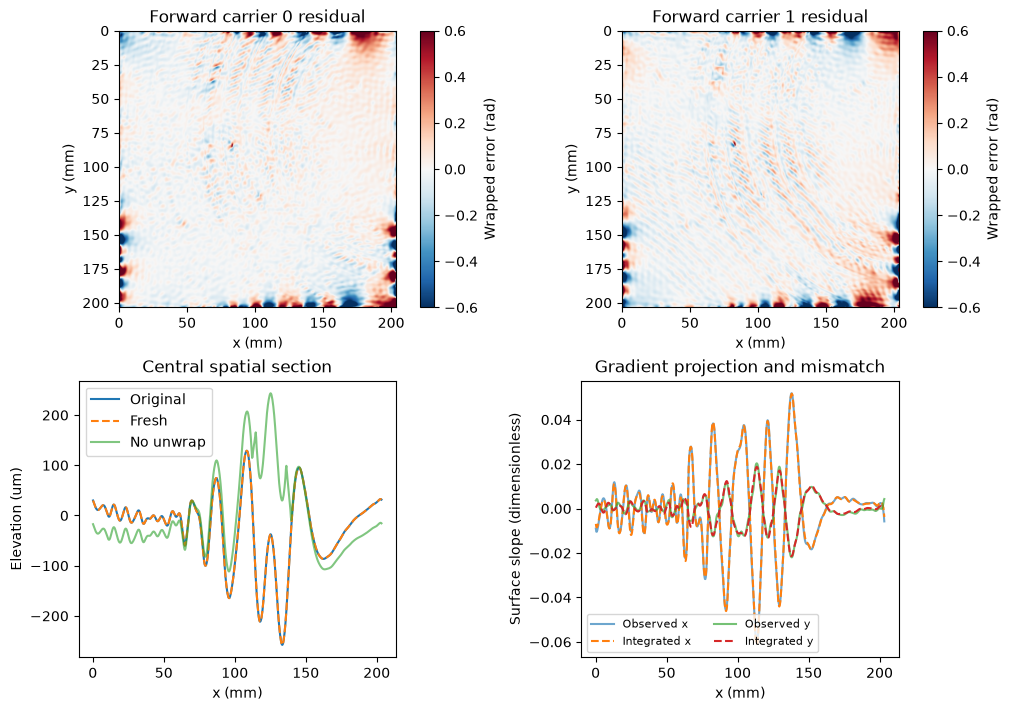

Maximum fresh/original height difference: 1.6263032587282567e-19 m


In [3]:
plots,error=figures(reference,measurements,fresh,upstream,diagnostics,variants)
for name,fig in plots.items():
    display(fig);plt.close(fig)
print('Maximum fresh/original height difference:',float(np.max(abs(fresh-upstream))),'m')
if os.environ.get('PRIVATE_FIGURES'):
    export(plots,os.environ['PRIVATE_FIGURES'],dict(reference=reference,measurements=measurements,fresh_height=fresh,upstream_height=upstream,phases=diagnostics['phases'],displacement=diagnostics['displacement'],gradient=diagnostics['gradient'],forward_phase_error=error,**variants),rows)


## Interpretation and limitations

The measured wave pattern produces a spatial relative-height field. Source parity, analytic unwrapping, known-mode integration and a wrapped-phase forward residual test different aspects of the result. The reference result explains the measured carrier phases substantially better than a zero surface; the fresh no-unwrapping comparison exposes phase-cycle artifacts.

There is no independent experimental elevation truth, noise-variance calibration or absolute tilt recovery. Illumination changes, nonideal perspective, discarded mean slopes, nonintegrable observation errors and finite periodic boundaries remain limitations. The original full-frame opaque probe is outside the selected transparent field, and no artificial values fill its occlusion. The output should be interpreted as the periodic relative component over this specified field of view.